# Проект 1. Использование сервисов и отмены подписок после обращений в поддержку ПРАЙМ

## Бизнес-вопрос
Как меняются использование сервисов и сохранение подписки после обращения в поддержку в зависимости от темы обращения? Какие ситуации стоит приоритетно разбирать командам поддержки и продукта?

## Исходная гипотеза
У клиентов с обращениями о доступе к сервисам использование в следующие 30 суток снижается сильнее относительно предыдущих 30 суток, чем у клиентов с обращениями о кэшбэке.

Проблема доступа может непосредственно препятствовать использованию, тогда как проблема с бонусами не обязательно мешает пользоваться сервисами. Это предположение проверяем по данным.

## Логика исследования

### 1. Изменение использования сервисов
Сравниваем сессии одних и тех же клиентов за 30 суток до и после первого обращения за июнь 2026 года.

Основной показатель - число сессий на клиента, включая клиентов без сессий. Дополнительные показатели - доля активных и число сессий на активного клиента.

Общее число сессий состоит из: число клиентов * долю активных * сессии на активного

Сравниваем все категории обращений, отдельно рассматриваем доступ и кэшбэк для проверки исходной гипотезы. Проверяем устойчивость результатов без повторных обращений.

### 2. Отмены подписок после обращения
В ходе исследования возник дополнительный вопрос: сопровождается ли наблюдаемая динамика использования отменами подписок?

Среди клиентов первой части выделяем владельцев подписок, действовавших в момент обращения. Рассчитываем долю владельцев, чья подписка отменена за следующие 30 суток, по категориям обращений.

### 3. Связь использования и отмен
Внутри каждой категории обращения сравниваем долю отмен между владельцами с ростом, снижением и неизменным количеством сессий. Отдельно выделяем отсутствие сессий в обоих окнах.

## Границы интерпретации
* Исследование описывает поведение после обращения, но не доказывает влияние самого обращения или работы поддержки: сопоставимой группы клиентов без обращений в анализе нет.
* Сессии относятся к клиенту, а не к конкретной подписке.
* Отмена действовавшей подписки не равна окончательному уходу: повторное оформление и сохранение доступа через шеринг не проверяются.
* Изменение использования и отмены наблюдаются в одном периоде. Отмена могла сама привести к сокращению числа сессий.

## Данные и методика

Используем четыре таблицы:
- `support_tickets` - обращения и их категории;
- `clients` - клиенты и даты регистрации;
- `service_usage` - сессии использования сервисов;
- `subscriptions` - владельцы, даты начала и отмены подписок.

### 1. Общая выборка и уровень детализации

Берем первое обращение каждого клиента за июнь 2026 года, а не первое обращение за всю историю. При совпадении времени порядок определяется по `ticket_id`. Категория выбранного обращения задаёт группу клиента.

Включаем клиентов, зарегистрированных не менее чем за 30 суток до обращения.

Одна строка основной аналитической таблицы - один клиент с выбранным обращением и показателями использования за два окна. Такой уровень позволяет сравнивать поведение одного человека без повторного учета из-за нескольких обращений.

Клиентов без сессий сохраняем с нулевыми значениями. Наличие собственной подписки не является условием этой части: сессии привязаны к человеку, а сервисы доступны также через шеринг. Наличие доступа для каждой отдельной сессии не проверяется.

### 2. Периоды и качество данных

Время считаем в UTC. Для момента обращения t:
- использование до: [t - 30 суток, t);
- использование после: [t, t + 30 суток).

Сессия относится к окну по времени начала. Учитываем только сессии с окончанием строго позже начала. Незакрытые обращения сохраняем: точка отсчёта - создание обращения, а не решение проблемы.

Июнь выбран до расчёта результатов: оба окна попадают в май-июль, где записи есть за каждый день. Однако наличие записей за каждый день не гарантирует полноту данных.

### 3. Использование сервисов и факторное разложение

Основной показатель - число сессий на всех клиентов категории. Активный клиент тот, у кого есть хотя бы одна корректная сессия в соответствующем окне.

Число сессий = число клиентов * доля активных * сессии на активного.

Число клиентов до и после одинаковое. Используем цепные подстановки: сначала заменяем долю активных, затем число сессий на активного. Сумма вкладов проверяется для каждой категории.

Дополнительно рассматриваем переходы между наличием и отсутствием сессий. Состав активных до и после может различаться.

### 4. Отмены подписок

Из общей выборки выделяем владельцев подписок, действовавших в момент обращения. У каждого в этой выборке ровно одна действовавшая подписка, поэтому число подписок совпадает с числом владельцев. Участников чужих подписок отдельно как владельцев не учитываем.

Доля отмен = число владельцев с отменой выбранной подписки в окне / число владельцев действующей подписки в момент обращения.

Учитываем все причины отмен, отдельно подсчитываем `payment_failed`. Поэтому показатель включает как отказ от подписки, так и отмены из-за сбоя оплаты. Отмены до обращения на этой выборке не сравниваем.

### 5. Связь использования и отмен

Соединяем сессии и подписки по клиенту с проверкой «один к одному».
В каждой категории обращения выделяем владельцев:
- с уменьшением числа сессий;
- с увеличением числа сессий;
- с неизменным положительным числом сессий;
- без сессий в обоих окнах.

Для каждой группы показываем число владельцев, число отмен и долю отмен. Использование и отмены измеряются в одном периоде, поэтому отмена могла сама сократить использование.

### 6. Проверка устойчивости

Повторяем сравнение использования без клиентов с другими обращениями в пределах обоих окон. Проверка относится к метрикам использования, а не к долям отмен.

Важно отметить, что различия между категориями не интерпретируются как причинный эффект обращения или поддержки.

## 1. Подключение к базе

В каждом соединении устанавливаю UTC, чтобы границы временных окон рассчитывались одинаково

In [1]:
import pandas as pd
from sqlalchemy import text
from prime.config import get_engine

engine = get_engine()


def q(sql, **params):
    """Выполнить SQL-запрос и вернуть таблицу pandas."""
    try:
        with engine.connect() as conn:
            conn.execute(text("set time zone 'UTC'"))
            return pd.read_sql(text(sql), conn, params=params)
    finally:
        engine.dispose()


q("select current_user as login, current_database() as database")

,login,database
0,yuabelaya,prime


## 2. Проверка исходных данных

### 2.1. Категории и даты обращений

Для каждой категории считаю количество обращений и уникальных клиентов, определяю даты первого и последнего обращения. Это помогает оценить объём данных и доступный период исследования.

Проверяю количество незакрытых обращений и случаев, когда дата закрытия раньше даты создания. Незакрытые обращения сохраняю: поведение клиентов изучается относительно создания обращения, а не его закрытия.

На этом этапе рассматриваю всю историю обращений, далее буду формировать выборку по периоду. Один клиент может обращаться по нескольким темам, поэтому
числа уникальных клиентов разных категорий нельзя складывать.

In [2]:
ticket_overview = q("""
    select
        category,
        count(*) as tickets,
        count(distinct client_id) as clients,
        min(created_at) as first_ticket,
        max(created_at) as last_ticket,
        count(*) filter (
            where resolved_at is null
        ) as unresolved,
        count(*) filter (
            where resolved_at < created_at
        ) as invalid_dates
    from prime.support_tickets
    group by category
    order by tickets desc
""")

ticket_overview

,category,tickets,clients,first_ticket,last_ticket,unresolved,invalid_dates
0,оплата,40663,37912,2025-01-06 00:53:02+00:00,2026-08-29 23:25:45+00:00,3326,0
1,доступ к сервису,31328,29734,2025-01-06 00:17:45+00:00,2026-08-29 23:47:38+00:00,2491,0
2,кэшбэк,24269,23239,2025-01-06 03:48:37+00:00,2026-08-29 23:56:07+00:00,1947,0
3,шеринг,20883,20146,2025-01-06 01:04:14+00:00,2026-08-29 23:36:51+00:00,1664,0
4,отмена подписки,19416,18787,2025-01-06 00:10:40+00:00,2026-08-29 23:01:30+00:00,1516,0
5,прочее,13441,13126,2025-01-06 05:19:13+00:00,2026-08-29 21:33:54+00:00,1021,0


### 2.2. Покрытие и данные об использовании

По каждому месяцу определяю количество сессий, даты первой и последней сессии и число дней с записями. Это нужно, чтобы выбрать период обращений с доступными данными за 30 суток до и после каждого обращения.

Проверяю пропуски клиента и окончания сессии, а также сессии с нулевой или отрицательной длительностью, такие сессии учитываться не будут

Для исследования выбираю обращения за июнь 2026 года: оба окна попадают в май-июль, где записи есть за каждый день. Так окна не затрагивают апрельские пропуски и неполный август.

In [3]:
usage_overview = q("""
    select
        to_char(started_at, 'YYYY-MM') as month,
        min(started_at) as first_session,
        max(started_at) as last_session,
        count(distinct started_at::date) as days_with_data,
        count(*) as sessions,
        count(*) filter (
            where ended_at is null
        ) as missing_end,
        count(*) filter (
            where ended_at <= started_at
        ) as nonpositive_duration,
        count(*) filter (
            where client_id is null
        ) as missing_client
    from prime.service_usage
    group by 1
    order by 1
""")

print(usage_overview.to_string(index=False))

  month             first_session              last_session  days_with_data  sessions  missing_end  nonpositive_duration  missing_client
2025-01 2025-01-06 00:00:05+00:00 2025-01-31 23:59:57+00:00              26    222754            0                   413               0
2025-02 2025-02-01 00:00:05+00:00 2025-02-28 23:59:59+00:00              28    256052            0                   501               0
2025-03 2025-03-01 00:00:04+00:00 2025-03-31 23:59:55+00:00              31    303031            0                   572               0
2025-04 2025-04-01 00:00:03+00:00 2025-04-30 23:59:56+00:00              30    310731            0                   622               0
2025-05 2025-05-01 00:00:10+00:00 2025-05-31 23:59:49+00:00              31    337556            0                   667               0
2025-06 2025-06-01 00:00:08+00:00 2025-06-30 23:59:51+00:00              30    341538            0                   714               0
2025-07 2025-07-01 00:00:23+00:00 2025-07

## 3. Формирование исследуемой группы

Выбираю первое обращение каждого клиента за июнь 2026 года. Для этого нумерую обращения внутри клиента по времени
и оставляю первое. При совпадении времени использую `ticket_id`.

Оставляю клиентов, зарегистрированных минимум за 30 суток до обращения, чтобы у каждого было полное окно наблюдения после регистрации.

Проверяю уникальность клиентов и считаю размер каждой категории. Дополнительно смотрю, сколько клиентов обращалось повторно
за июнь. Это предварительная проверка: повторные обращения в полных окнах до и после будут рассмотрены отдельно.

In [4]:
# Правила выборки обсуждены с ИИ
cohort_sql = """
    with ranked_tickets as (
        select
            ticket_id,
            client_id,
            category,
            created_at,
            -- считаю все июньские обращения клиента, не сворачивая строки
            count(*) over (
                partition by client_id
            ) as june_tickets,
            -- Нумерую обращения внутри клиента по времени
            -- ticket_id задаёт однозначный порядок при совпадении времени
            row_number() over (
                partition by client_id
                order by created_at, ticket_id
            ) as rn
        from prime.support_tickets
        where created_at >= '2026-06-01'
          and created_at < '2026-07-01'
    )
    select
        t.ticket_id,
        t.client_id,
        t.category,
        t.created_at as ticket_at,
        c.registered_at,
        t.june_tickets
    from ranked_tickets t
    join prime.clients c on t.client_id = c.client_id
    where t.rn = 1
      and c.registered_at <= t.created_at - interval '30 days'
"""

cohort = q(cohort_sql)

assert cohort["client_id"].is_unique, "Клиент попал в выборку несколько раз"

cohort_summary = (
    cohort.groupby("category", dropna=False)
    .agg(
        clients=("client_id", "size"),
        clients_with_repeat_tickets=(
            "june_tickets", lambda x: (x > 1).sum()
        )
    )
    .sort_values("clients", ascending=False)
)

print("Всего клиентов в исследовании:", len(cohort))
cohort_summary

Всего клиентов в исследовании: 9406


,clients,clients_with_repeat_tickets
category,,
оплата,2594,42
доступ к сервису,1924,23
кэшбэк,1539,27
шеринг,1286,26
отмена подписки,1226,18
прочее,837,13


## 4. Изменение использования сервисов

### 4.1. Сессии каждого клиента до и после обращения

Для каждого клиента считаю корректные сессии за 30 суток до выбранного обращения и за 30 суток после него. Сессию отношу к окну по моменту начала.

Использую left join, чтобы сохранить клиентов без сессий.

In [5]:
# ИИ помог реализовать индивидуальные окна до/после и сохранить клиентов без сессий
activity = q(f"""
    with cohort as (
        {cohort_sql}
    )
    select
        c.client_id,
        c.category,
        c.ticket_at,
        count(u.usage_id) filter (
            where u.started_at < c.ticket_at
        ) as sessions_before,
        count(u.usage_id) filter (
            where u.started_at >= c.ticket_at
        ) as sessions_after
    from cohort c
    left join prime.service_usage u
        on u.client_id = c.client_id -- клиент остается даже без подходящих сессий
        and u.started_at >= c.ticket_at - interval '30 days'
        and u.started_at < c.ticket_at + interval '30 days'
        and u.ended_at > u.started_at
    group by c.client_id, c.category, c.ticket_at
""")

assert activity["client_id"].is_unique # каждый клиент представлен один раз
assert set(activity["client_id"]) == set(cohort["client_id"]) # состав клиентов после соединения совпадает с исходной выборкой

print("Клиентов после соединения:", len(activity))
print(
    "Без сессий в обоих окнах:",
    ((activity["sessions_before"] == 0)
     & (activity["sessions_after"] == 0)).sum()
)

activity.groupby("category", dropna=False).agg(
    clients=("client_id", "size"),
    sessions_before=("sessions_before", "sum"),
    sessions_after=("sessions_after", "sum")
)

Клиентов после соединения: 9406
Без сессий в обоих окнах: 4558


,clients,sessions_before,sessions_after
category,,,
доступ к сервису,1924,1837,1898
кэшбэк,1539,1625,1735
оплата,2594,2748,2820
отмена подписки,1226,1075,1178
прочее,837,898,892
шеринг,1286,1331,1356


### 4.2. Метрики для сравнения категорий

Категории различаются по числу клиентов, поэтому сравниваю не только суммарные сессии, но и показатели на клиента.

Для каждого окна рассчитываю:
- сессии на всех клиентов группы;
- долю клиентов хотя бы с одной корректной сессией;
- сессии на активного клиента

Основная метрика включает клиентов с нулевой активностью. Активность здесь означает использование сервисов, а не наличие действующей подписки.

In [6]:
metrics = activity.groupby("category", dropna=False).agg(
    clients=("client_id", "size"),
    sessions_before=("sessions_before", "sum"),
    sessions_after=("sessions_after", "sum"),
    active_before=("sessions_before", lambda x: (x > 0).sum()), # ИИ помог записать подсчёт активных клиентов
    active_after=("sessions_after", lambda x: (x > 0).sum())
)

for period in ["before", "after"]:
    metrics[f"per_client_{period}"] = (
        metrics[f"sessions_{period}"] / metrics["clients"]
    )
    metrics[f"active_share_{period}"] = (
        metrics[f"active_{period}"] / metrics["clients"]
    )
    metrics[f"per_active_{period}"] = (
        metrics[f"sessions_{period}"]
        / metrics[f"active_{period}"].replace(0, float("nan")) # защита от деления на 0
    )

comparison = pd.DataFrame({
    "Клиентов": metrics["clients"],
    "Сессий на клиента до": metrics["per_client_before"],
    "Сессий на клиента после": metrics["per_client_after"],
    "Изменение на клиента": (
        metrics["per_client_after"] - metrics["per_client_before"]
    ),
    "Активных до, %": metrics["active_share_before"] * 100,
    "Активных после, %": metrics["active_share_after"] * 100,
    "Изменение активности, п.п.": (
        metrics["active_share_after"] - metrics["active_share_before"]
    ) * 100
})

print(comparison.round(3).to_string())

                  Клиентов  Сессий на клиента до  Сессий на клиента после  Изменение на клиента  Активных до, %  Активных после, %  Изменение активности, п.п.
category                                                                                                                                                      
доступ к сервису      1924                 0.955                    0.986                 0.032          38.565             40.489                       1.923
кэшбэк                1539                 1.056                    1.127                 0.071          40.221             41.910                       1.689
оплата                2594                 1.059                    1.087                 0.028          41.056             40.979                      -0.077
отмена подписки       1226                 0.877                    0.961                 0.084          36.623             38.254                       1.631
прочее                 837                 1.0

### 4.3. Факторное разложение изменения числа сессий

Разделяю изменение использования на два вклада: изменение доли активных и изменение частоты среди активных.

Использую равенство, где число сессий = число клиентов * доля активных * сессии на активного.

Число клиентов в каждом окне одинаковое, поэтому его вклад равен нулю. Сначала заменяю долю активных значением после обращения, затем - частоту. Порядок подстановок фиксирую, поскольку от него зависят величины отдельных вкладов.

Проверяю, что сумма вкладов совпадает с фактическим изменением. Дробные вклады являются расчётными величинами, а не отдельными наблюдаемыми сессиями.

In [7]:
# Число клиентов в каждой группе до и после одинаковое
# Порядок подстановок: доля активных -> сессии на активного

factor_effects = pd.DataFrame(index=metrics.index)

factor_effects["Вклад доли активных"] = (
    metrics["clients"]
    * (metrics["active_share_after"] - metrics["active_share_before"])
    * metrics["per_active_before"]
)

factor_effects["Вклад частоты среди активных"] = (
    metrics["clients"]
    * metrics["active_share_after"]
    * (metrics["per_active_after"] - metrics["per_active_before"])
)

factor_effects["Изменение числа сессий"] = (
    metrics["sessions_after"] - metrics["sessions_before"]
)

factor_effects["Ошибка сверки"] = (
    factor_effects["Вклад доли активных"]
    + factor_effects["Вклад частоты среди активных"]
    - factor_effects["Изменение числа сессий"]
)

assert factor_effects["Ошибка сверки"].abs().max() < 1e-8, (
    "Вклады не сошлись с изменением числа сессий"
) # ИИ предложил допуск 1e-8 вместо точного равенства вычисления с дробными числами могут давать малую погрешность

print(factor_effects.round(3).to_string())

                  Вклад доли активных  Вклад частоты среди активных  Изменение числа сессий  Ошибка сверки
category                                                                                                  
доступ к сервису               91.602                       -30.602                      61            0.0
кэшбэк                         68.255                        41.745                     110            0.0
оплата                         -5.161                        77.161                      72           -0.0
отмена подписки                47.884                        55.116                     103           -0.0
прочее                         67.497                       -73.497                      -6            0.0
шеринг                          7.591                        17.409                      25            0.0


### 4.4. Переходы клиентов между активностью и её отсутствием

Среднее изменение может скрывать противоположное поведение разных клиентов. Поэтому выделяю четыре группы: активные в обоих окнах, только до, только после и неактивные в обоих окнах. Проверяю, что группы охватывают всех клиентов каждой категории.

Отдельно рассчитываю долю клиентов без сессий после обращения среди активных до него. Это показатель прекращения использования в наблюдаемом окне, а не доля отмен подписок и не доказательство окончательного ухода.

In [8]:
before_active = activity["sessions_before"] > 0
after_active = activity["sessions_after"] > 0

# ИИ предложил разбиение на четыре перехода активности и помог реализовать его
transitions = (
    activity.assign(
        active_both=before_active & after_active,
        before_only=before_active & ~after_active,
        after_only=~before_active & after_active,
        inactive_both=~before_active & ~after_active
    )
    .groupby("category", dropna=False)[[
        "active_both", "before_only", "after_only", "inactive_both"
    ]]
    .sum()
    .rename(columns={
        "active_both": "Активны в обоих окнах",
        "before_only": "Активны только до",
        "after_only": "Активны только после",
        "inactive_both": "Неактивны в обоих"
    })
)

assert transitions.sum(axis=1).eq(metrics["clients"]).all() # axis=1: складываю столбцы внутри каждой строки-категории
# eq сравнивает с числом клиентов; all требует совпадения во всех строках

transitions["Без сессий после среди активных до, %"] = (
    transitions["Активны только до"]
    / metrics["active_before"] * 100
)

print(transitions.round(2).to_string())

                  Активны в обоих окнах  Активны только до  Активны только после  Неактивны в обоих  Без сессий после среди активных до, %
category                                                                                                                                  
доступ к сервису                    533                209                   246                936                                  28.17
кэшбэк                              449                170                   196                724                                  27.46
оплата                              750                315                   313               1216                                  29.58
отмена подписки                     333                116                   136                641                                  25.84
прочее                              221                 85                   108                423                                  27.78
шеринг                     

### 4.5. График: использование до и после по категориям

Сравниваю число сессий на клиента за два равных окна. Знаменатель включает всех клиентов категории, в том числе не пользовавшихся сервисами.

Располагаю категории по изменению показателя, чтобы показать, где использование выросло или снизилось.

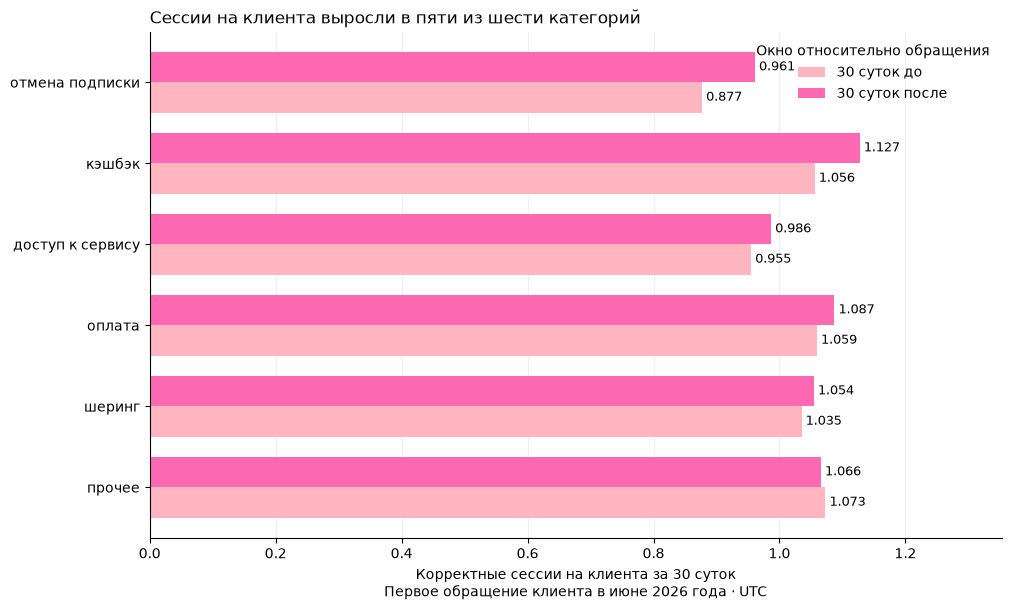

In [9]:
import matplotlib.pyplot as plt
# все графики делала с ИИ, говорила ему что хочу видеть)

plot_data = comparison.sort_values("Изменение на клиента")[
    ["Сессий на клиента до", "Сессий на клиента после"]
].rename(columns={
    "Сессий на клиента до": "30 суток до",
    "Сессий на клиента после": "30 суток после"
})

fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")

plot_data.plot.barh(
    ax=ax,
    color=["lightpink", "hotpink"],
    width=0.75
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9)

ax.set_title(
    "Сессии на клиента выросли в пяти из шести категорий",
    loc="left"
)
ax.set_xlabel(
    "Корректные сессии на клиента за 30 суток\n"
    "Первое обращение клиента в июне 2026 года · UTC"
)
ax.set_ylabel("")
ax.set_xlim(0, plot_data.max().max() * 1.2)
ax.spines[["top", "right"]].set_visible(False)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)
ax.legend(frameon=False, title="Окно относительно обращения")

plt.show()

### 4.6. График: факторы изменения в группах исходной гипотезы

Показываю факторное разложение для обращений о доступе и кэшбэке. Пересчитываю вклады на 100 клиентов, чтобы сравнение не зависело от размера групп.

Первый шаг - вклад доли активных, второй - вклад частоты среди активных, третий - итог.

Это арифметическое объяснение изменения. Поскольку состав активных клиентов до и после различается, снижение частоты среди активных не означает, что каждый клиент стал пользоваться реже.

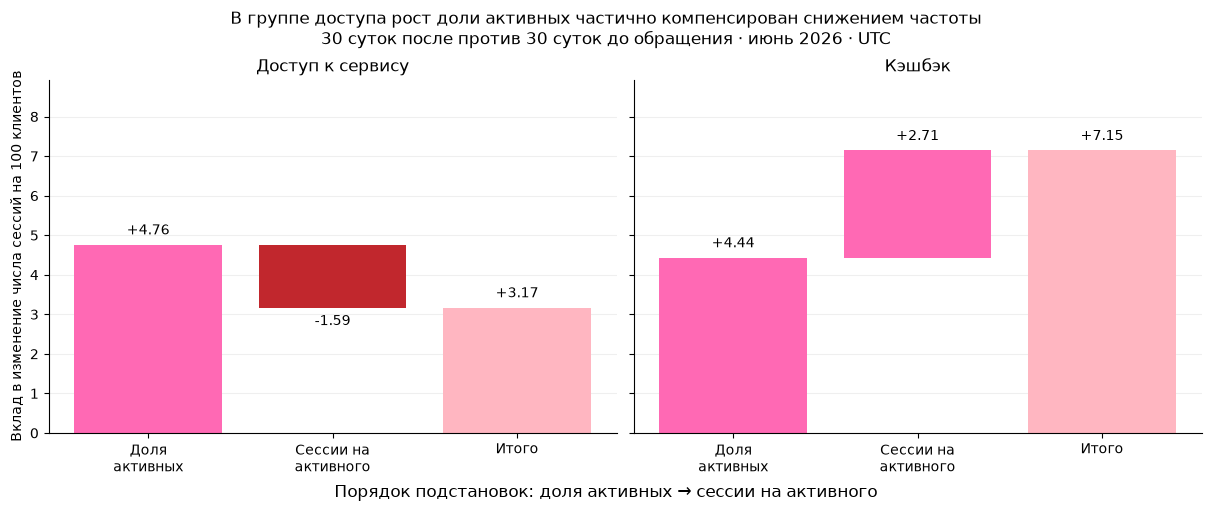

In [10]:
categories = ["доступ к сервису", "кэшбэк"]

effects_per_100 = factor_effects[
    ["Вклад доли активных", "Вклад частоты среди активных"] # каждую строку делю на число клиентов соответствующей категории
].div(metrics["clients"], axis=0) * 100

fig, axes = plt.subplots(
    1, 2, figsize=(12, 5), sharey=True, layout="constrained"
)

upper_limits = []

for ax, category in zip(axes, categories):
    steps = effects_per_100.loc[category]
    total = steps.sum()

    values = [steps.iloc[0], steps.iloc[1], total]
    bottoms = [0, steps.iloc[0], 0]
    colors = [
        "hotpink" if value >= 0 else "#C1272D"
        for value in values[:2]
    ] + ["lightpink"]

    bars = ax.bar(
        ["Доля\nактивных", "Сессии на\nактивного", "Итого"],
        values,
        bottom=bottoms,
        color=colors
    )

    ax.bar_label(
        bars,
        labels=[f"{value:+.2f}" for value in values],
        padding=5
    )
    ax.set_title(category.capitalize())
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)

    upper_limits.append(max(steps.iloc[0], total))

axes[0].set_ylabel("Вклад в изменение числа сессий на 100 клиентов")
axes[0].set_ylim(0, max(upper_limits) * 1.25)

fig.suptitle(
    "В группе доступа рост доли активных частично компенсирован снижением частоты\n"
    "30 суток после против 30 суток до обращения · июнь 2026 · UTC"
)
fig.supxlabel("Порядок подстановок: доля активных → сессии на активного")

plt.show()

### 4.7. График: индивидуальные переходы активности

Показываю состав каждой категории по четырём переходам активности. Все доли рассчитаны от полного числа клиентов категории и в сумме составляют 100%. График помогает увидеть, какие разные ситуации скрывает общее изменение использования.

Доля активных только до на этом графике отличается от показателя «без сессий после среди активных до»: здесь знаменатель - все клиенты категории, а там - только ранее активные.

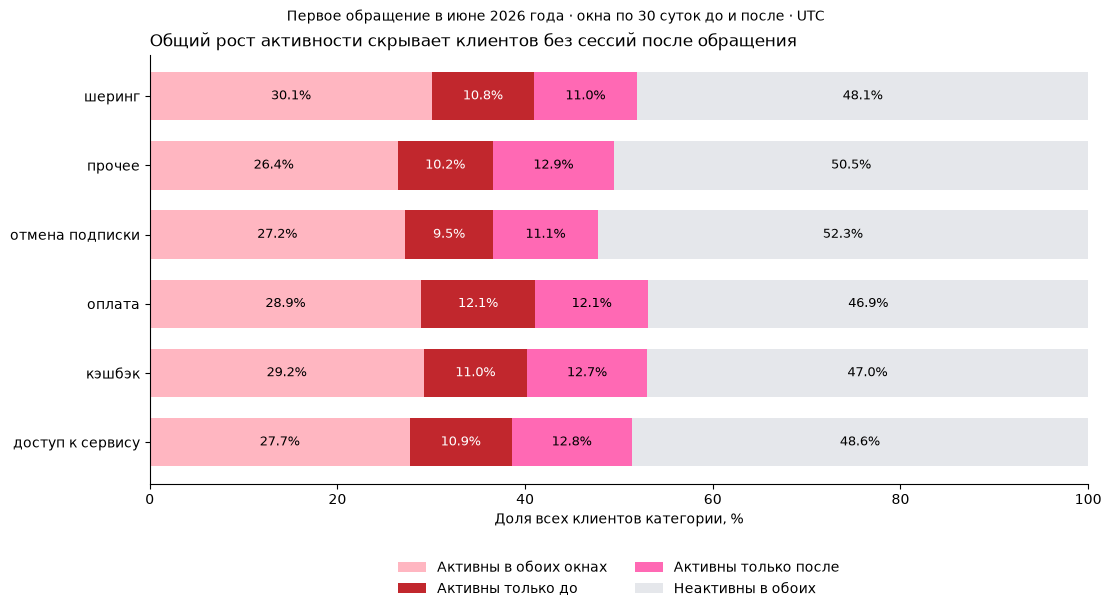

In [11]:
transition_columns = [
    "Активны в обоих окнах",
    "Активны только до",
    "Активны только после",
    "Неактивны в обоих"
]

transition_pct = (
    transitions[transition_columns]
    .div(metrics["clients"], axis=0)
    * 100
)

assert (transition_pct.sum(axis=1) - 100).abs().max() < 1e-8

fig, ax = plt.subplots(figsize=(11, 6), layout="constrained")

transition_pct.plot.barh(
    stacked=True,
    ax=ax,
    color=["lightpink", "#C1272D", "hotpink", "#E5E7EB"],
    width=0.7
)

for i, container in enumerate(ax.containers):
    ax.bar_label(
        container,
        labels=[f"{value:.1f}%" for value in transition_pct.iloc[:, i]],
        label_type="center",
        color="white" if i == 1 else "black",
        fontsize=9
    )

ax.set_title(
    "Общий рост активности скрывает клиентов без сессий после обращения",
    loc="left"
)
ax.set_xlabel("Доля всех клиентов категории, %")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=2,
    frameon=False
)

fig.suptitle(
    "Первое обращение в июне 2026 года · окна по 30 суток до и после · UTC",
    fontsize=10
)

plt.show()

## 5. Проверка устойчивости результатов использования

### 5.1. Расчёт без других обращений в обоих окнах

Проверяю, не связано ли направление результатов с повторными обращениями. Считаю другие обращения каждого клиента за 30 суток до и после выбранного обращения, независимо от темы.

Повторяю сравнение сессий на клиента только для тех, у кого других обращений в этих окнах нет. Сопоставляю изменение с результатом основной выборки.

Это дополнительная проверка, так как исключенные клиенты могут отличаться по характеру проблем.

In [12]:
# я описала ИИ логику проверки без других обращений в обоих окнах и ИИ помог с верным запросом
repeat_check = q(f"""
    with cohort as (
        {cohort_sql}
    )
    select
        c.client_id,
        count(t.ticket_id) as other_tickets
    from cohort c
    left join prime.support_tickets t
        on t.client_id = c.client_id
        and t.ticket_id <> c.ticket_id
        and t.created_at >= c.ticket_at - interval '30 days'
        and t.created_at < c.ticket_at + interval '30 days'
    group by c.client_id
""")

activity_checked = activity.merge(
    repeat_check,
    on="client_id",
    how="left",
    validate="1:1"
)

assert activity_checked["other_tickets"].notna().all()

single_ticket = activity_checked[
    activity_checked["other_tickets"] == 0
]

sensitivity = single_ticket.groupby("category").agg(
    clients_without_other_tickets=("client_id", "size"),
    before=("sessions_before", "mean"),
    after=("sessions_after", "mean")
)

sensitivity["change_without_other_tickets"] = (
    sensitivity["after"] - sensitivity["before"]
)
sensitivity["change_main_sample"] = (
    metrics["per_client_after"] - metrics["per_client_before"]
)
sensitivity["clients_main_sample"] = metrics["clients"]

print(sensitivity.round(4).to_string())

                  clients_without_other_tickets  before   after  change_without_other_tickets  change_main_sample  clients_main_sample
category                                                                                                                              
доступ к сервису                           1834  0.9493  0.9913                        0.0420              0.0317                 1924
кэшбэк                                     1465  1.0464  1.1270                        0.0805              0.0715                 1539
оплата                                     2474  1.0530  1.0873                        0.0344              0.0278                 2594
отмена подписки                            1168  0.8690  0.9658                        0.0967              0.0840                 1226
прочее                                      798  1.0852  1.0802                       -0.0050             -0.0072                  837
шеринг                                     1222  1.0360

### 5.2. График: основной результат и проверка устойчивости

Сравниваю изменение использования в полной выборке и среди клиентов без других обращений в обоих окнах. Выражаю изменения в сессиях на 100 клиентов

Проверяю, сохраняется ли направление изменения в каждой категории после дополнительного отбора.

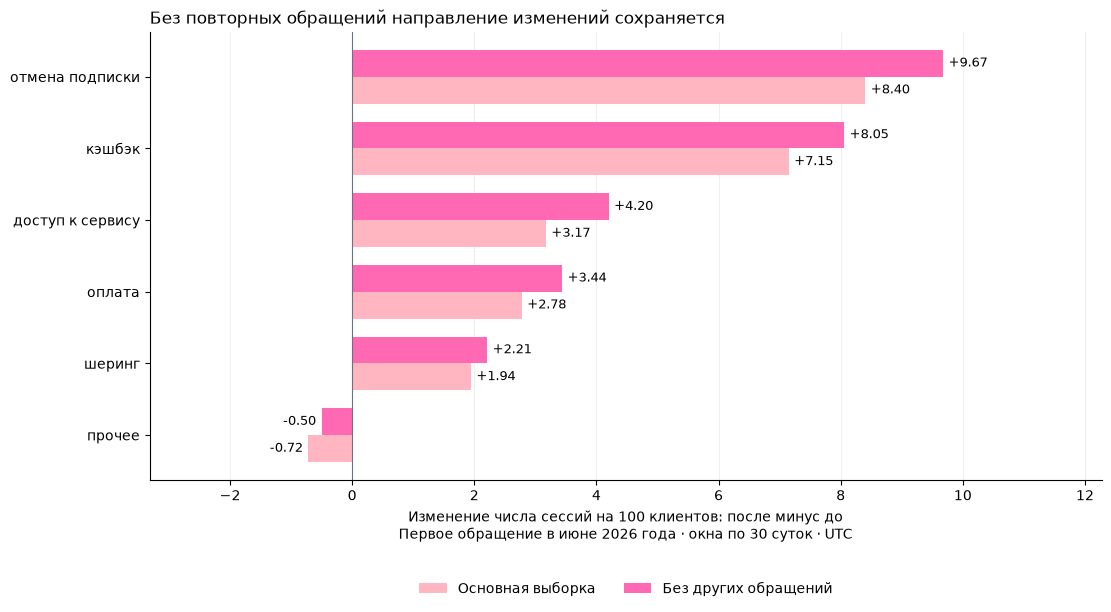

In [13]:
robustness_plot = (
    sensitivity[[
        "change_main_sample",
        "change_without_other_tickets"
    ]]
    .rename(columns={
        "change_main_sample": "Основная выборка",
        "change_without_other_tickets": "Без других обращений"
    })
    .sort_values("Основная выборка")
    * 100
)

fig, ax = plt.subplots(figsize=(11, 6), layout="constrained")

robustness_plot.plot.barh(
    ax=ax,
    color=["lightpink", "hotpink"],
    width=0.75
)

for container in ax.containers:
    ax.bar_label(container, fmt="%+.2f", padding=4, fontsize=9)

ax.axvline(0, color="#6B7280", linewidth=0.8)
ax.set_title(
    "Без повторных обращений направление изменений сохраняется",
    loc="left"
)
ax.set_xlabel(
    "Изменение числа сессий на 100 клиентов: после минус до\n"
    "Первое обращение в июне 2026 года · окна по 30 суток · UTC"
)
ax.set_ylabel("")
ax.margins(x=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.2),
    ncol=2,
    frameon=False
)

plt.show()

## 6. Отмены подписок после обращения

### 6.1. Проверка данных о подписках

Изменение сессий не показывает, сохранил ли клиент подписку, поэтому дополнительно исследую её отмену.

Сначала проверяю даты, наличие владельца и причины отмен: нет ли окончания раньше начала или одновременно с ним, отмен без причины и причин отмены без даты окончания.

Среди причин есть `payment_failed`, поэтому не каждую отмену можно интерпретировать как добровольный отказ клиента.

In [14]:
subscription_overview = q("""
    select
        cancel_reason,
        count(*) as subscriptions,
        count(*) filter (
            where ended_at is null
        ) as without_end,
        count(*) filter (
            where ended_at is not null
        ) as with_end,
        count(*) filter (
            where ended_at <= started_at
        ) as invalid_dates,
        count(*) filter (
            where started_at is null
        ) as missing_start,
        count(*) filter (
            where owner_client_id is null
        ) as missing_owner,
        min(ended_at) as first_cancellation,
        max(ended_at) as last_cancellation
    from prime.subscriptions
    group by cancel_reason
    order by subscriptions desc
""")

print(subscription_overview.to_string(index=False))

 cancel_reason  subscriptions  without_end  with_end  invalid_dates  missing_start  missing_owner        first_cancellation         last_cancellation
           NaN         167978       167978         0              0              0              0                       NaT                       NaT
     not_using          56416            0     56416              0              0              0 2024-02-08 21:01:45+00:00 2026-08-28 23:47:06+00:00
 too_expensive          40050            0     40050              0              0              0 2024-02-09 21:51:03+00:00 2026-08-28 23:49:30+00:00
      switched          29973            0     29973              0              0              0 2024-02-06 00:08:24+00:00 2026-08-28 23:52:26+00:00
payment_failed          22964            0     22964              0              0              0 2024-02-08 02:55:24+00:00 2026-08-28 23:28:58+00:00
         other          16524            0     16524              0              0              0 20

### 6.2. Владельцы действующих подписок на момент обращения

Из исходной группы выделяю клиентов, владевших действующей подпиской в момент определенного обращения. Подписка должна начаться не позднее обращения и закончиться позже него либо не иметь даты окончания.

Просто отбирать строки без `ended_at` нельзя: это исключило бы клиентов, отменивших подписку после обращения.

Одна строка полученной таблицы - действовавшая подписка владельца. Проверяю число подписок на клиента, поскольку несколько подписок могли бы привести к повторному учету владельцев.

Участников чужих подписок отдельно в знаменатель не включаю.

In [15]:
subscriptions_at_ticket = q(f"""
    with cohort as (
        {cohort_sql}
    )
    select
        c.client_id,
        c.category,
        c.ticket_at,
        s.subscription_id,
        s.started_at,
        s.ended_at,
        s.cancel_reason,
        s.is_trial
    from cohort c
    join prime.subscriptions s
        on s.owner_client_id = c.client_id
        and s.started_at <= c.ticket_at
        and (
            s.ended_at is null
            or s.ended_at > c.ticket_at
        )
""")

assert subscriptions_at_ticket["subscription_id"].is_unique
assert set(subscriptions_at_ticket["client_id"]).issubset(
    set(cohort["client_id"]) # Проверяю, что все владельцы входят в исходную группу клиентов
)

subscriptions_per_owner = (
    subscriptions_at_ticket.groupby("client_id").size()
)

print("Клиентов в исходной выборке:", len(cohort))
print("Владельцев подписок на момент обращения:",
      len(subscriptions_per_owner))
print("Действовавших подписок:", len(subscriptions_at_ticket))
print("Владельцев нескольких действовавших подписок:",
      (subscriptions_per_owner > 1).sum())

owner_summary = subscriptions_at_ticket.groupby("category").agg(
    owners=("client_id", "nunique"),
    subscriptions=("subscription_id", "size")
)

print(owner_summary.to_string())

Клиентов в исходной выборке: 9406
Владельцев подписок на момент обращения: 3841
Действовавших подписок: 3841
Владельцев нескольких действовавших подписок: 0
                  owners  subscriptions
category                               
доступ к сервису     790            790
кэшбэк               623            623
оплата              1074           1074
отмена подписки      464            464
прочее               352            352
шеринг               538            538


### 6.3. Доля отмен за следующие 30 суток

Для каждой действовавшей подписки определяю, была ли она отменена после обращения и до истечения следующих 30 суток.

По каждой категории делю количество отмен на число владельцев действующей подписки в момент обращения. Отдельно считаю отмены с причиной `payment_failed` и проверяю, что сумма частей совпадает с общим числом отмен.

Это доля отмен после обращения. Она не показывает, насколько обращение изменило вероятность отмены. Отмена выбранной подписки также не исключает последующего оформления новой.

In [16]:
cancellation = subscriptions_at_ticket.copy()

cancellation["cancelled_30d"] = (
    cancellation["ended_at"].notna()
    & (cancellation["ended_at"] > cancellation["ticket_at"])
    & (
        cancellation["ended_at"]
        < cancellation["ticket_at"] + pd.Timedelta(days=30)
    )
)

cancellation["payment_failed_30d"] = (
    cancellation["cancelled_30d"]
    & cancellation["cancel_reason"].eq("payment_failed")
)

cancellation["other_cancellation_30d"] = (
    cancellation["cancelled_30d"]
    & ~cancellation["cancel_reason"].eq("payment_failed")
)

cancellation_summary = cancellation.groupby("category").agg(
    owners=("client_id", "size"),
    cancelled_30d=("cancelled_30d", "sum"),
    payment_failed_30d=("payment_failed_30d", "sum"),
    other_cancellation_30d=("other_cancellation_30d", "sum")
)

assert (
    cancellation_summary["payment_failed_30d"]
    + cancellation_summary["other_cancellation_30d"]
).eq(cancellation_summary["cancelled_30d"]).all()

cancellation_summary["cancelled_pct"] = (
    cancellation_summary["cancelled_30d"]
    / cancellation_summary["owners"] * 100
)

print(cancellation_summary.round(2).to_string())

                  owners  cancelled_30d  payment_failed_30d  other_cancellation_30d  cancelled_pct
category                                                                                          
доступ к сервису     790             27                   5                      22           3.42
кэшбэк               623             27                   3                      24           4.33
оплата              1074             42                   5                      37           3.91
отмена подписки      464             14                   2                      12           3.02
прочее               352             13                   1                      12           3.69
шеринг               538             15                   2                      13           2.79


## 7. Связь использования и отмен подписок

### 7.1. Отмены при разных изменениях использования

Соединяю сведения об отменах с ранее рассчитанными сессиями по клиенту.

Выделяю владельцев с ростом, снижением и неизменным положительным числом сессий. Отсутствие сессий в обоих окнах рассматриваю отдельно.

Для каждой группы рассчитываю долю отмен. Это сравнение проводится только среди владельцев действовавших подписок, а не среди всех клиентов исходной выборки.

Изменение использования и отмены наблюдаются в одном периоде, поэтому отмена могла сама привести к уменьшению числа сессий.

In [17]:
usage_and_cancellation = cancellation.merge(
    activity[["client_id", "sessions_before", "sessions_after"]],
    on="client_id",
    how="left",
    validate="1:1"
)

assert usage_and_cancellation[
    ["sessions_before", "sessions_after"]
].notna().all().all()

before = usage_and_cancellation["sessions_before"]
after = usage_and_cancellation["sessions_after"]

usage_and_cancellation["usage_change"] = "Без изменения, сессии есть"

usage_and_cancellation.loc[
    after > before, "usage_change"
] = "Сессий стало больше"

usage_and_cancellation.loc[
    after < before, "usage_change"
] = "Сессий стало меньше"

usage_and_cancellation.loc[
    (before == 0) & (after == 0), "usage_change"
] = "Нет сессий в обоих окнах"

cancellation_by_usage = usage_and_cancellation.groupby(
    "usage_change"
).agg(
    owners=("client_id", "size"),
    cancelled=("cancelled_30d", "sum"),
    mean_sessions_before=("sessions_before", "mean"),
    mean_sessions_after=("sessions_after", "mean")
)

cancellation_by_usage["cancelled_pct"] = (
    cancellation_by_usage["cancelled"]
    / cancellation_by_usage["owners"] * 100
)

assert cancellation_by_usage["owners"].sum() == len(cancellation)
assert (
    cancellation_by_usage["cancelled"].sum()
    == cancellation["cancelled_30d"].sum()
)

print(cancellation_by_usage.round(3).to_string())

                            owners  cancelled  mean_sessions_before  mean_sessions_after  cancelled_pct
usage_change                                                                                           
Без изменения, сессии есть     487         17                 1.889                1.889          3.491
Нет сессий в обоих окнах       814         34                 0.000                0.000          4.177
Сессий стало больше           1333         23                 1.173                3.068          1.725
Сессий стало меньше           1207         64                 3.169                1.291          5.302


### 7.2. Связь использования и отмен внутри категорий обращений

Объединяю три признака: тему обращения, изменение использования и факт отмены подписки.

Внутри каждой категории рассчитываю долю отмен для каждой группы изменения сессий. Это позволяет проверить, сохраняется ли связь, которую показала общая таблица, при разделении по темам обращений.

In [18]:
cancellation_by_category_usage = (
    usage_and_cancellation
    .groupby(["category", "usage_change"])
    .agg(
        owners=("client_id", "size"),
        cancelled=("cancelled_30d", "sum"),
        payment_failed=("payment_failed_30d", "sum")
    )
)

cancellation_by_category_usage["cancelled_pct"] = (
    cancellation_by_category_usage["cancelled"]
    / cancellation_by_category_usage["owners"] * 100
)

# Проверяем, что разбиение не потеряло клиентов и отмены.
check = cancellation_by_category_usage.groupby(
    level="category"
)[["owners", "cancelled"]].sum()

assert check["owners"].eq(cancellation_summary["owners"]).all()
assert check["cancelled"].eq(
    cancellation_summary["cancelled_30d"]
).all()

print(cancellation_by_category_usage.round(2).to_string())

                                             owners  cancelled  payment_failed  cancelled_pct
category         usage_change                                                                
доступ к сервису Без изменения, сессии есть     105          4               0           3.81
                 Нет сессий в обоих окнах       172          6               1           3.49
                 Сессий стало больше            260          2               1           0.77
                 Сессий стало меньше            253         15               3           5.93
кэшбэк           Без изменения, сессии есть      78          3               0           3.85
                 Нет сессий в обоих окнах       115          6               0           5.22
                 Сессий стало больше            238          9               1           3.78
                 Сессий стало меньше            192          9               2           4.69
оплата           Без изменения, сессии есть     136         

### 7.3. График: тема обращения, использование и отмены

На тепловой карте строки соответствуют категориям обращений, столбцы - изменению использования.

В каждой ячейке подписываю процент и отношение числа отмен к числу владельцев этой группы. Это позволяет оценивать результат вместе с размером выборки.

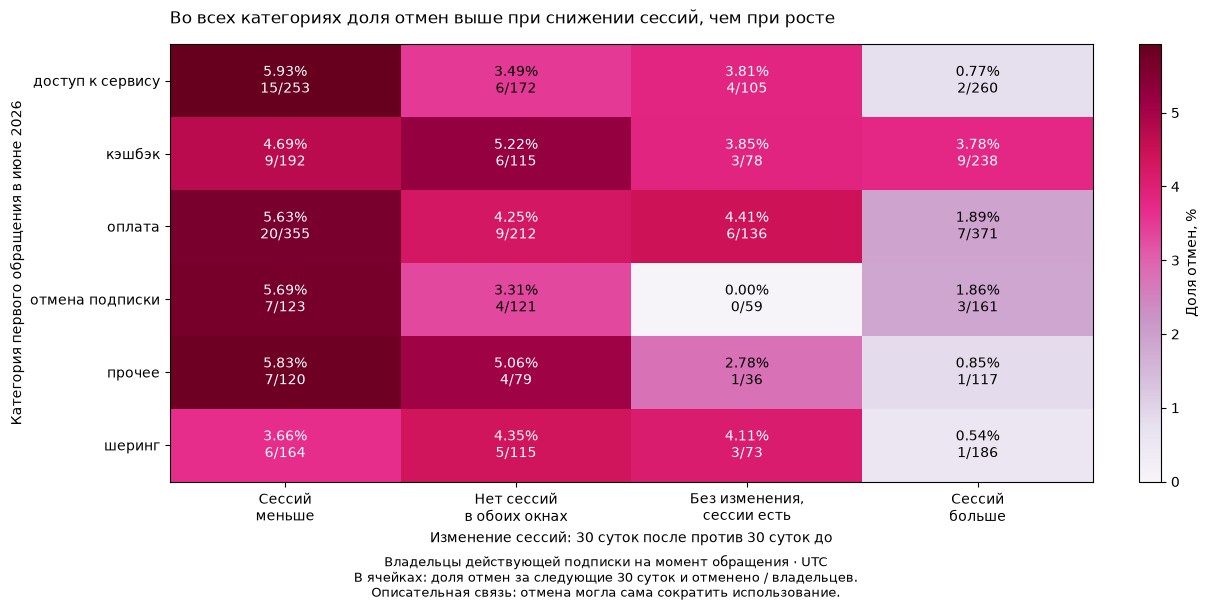

In [19]:
usage_order = [
    "Сессий стало меньше",
    "Нет сессий в обоих окнах",
    "Без изменения, сессии есть",
    "Сессий стало больше"
]

rates = cancellation_by_category_usage["cancelled_pct"].unstack(
    "usage_change"
).reindex(columns=usage_order) # ИИ помог преобразовать таблицу:
# категории остаются строками, группы изменения сессий становятся столбцами

owners = cancellation_by_category_usage["owners"].unstack(
    "usage_change"
).reindex(index=rates.index, columns=usage_order)

cancelled = cancellation_by_category_usage["cancelled"].unstack(
    "usage_change"
).reindex(index=rates.index, columns=usage_order)

fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")

vmax = rates.max().max()
image = ax.imshow(
    rates.to_numpy(),
    cmap="PuRd",
    vmin=0,
    vmax=vmax,
    aspect="auto"
)

ax.set_xticks(range(len(usage_order)), labels=[
    "Сессий\nменьше",
    "Нет сессий\nв обоих окнах",
    "Без изменения,\nсессии есть",
    "Сессий\nбольше"
])
ax.set_yticks(range(len(rates)), labels=rates.index)

for i in range(len(rates)):
    for j in range(len(usage_order)):
        value = rates.iloc[i, j]
        if pd.notna(value):
            label = (
                f"{value:.2f}%\n"
                f"{int(cancelled.iloc[i, j])}/{int(owners.iloc[i, j])}"
            )
            ax.text(
                j, i, label,
                ha="center", va="center",
                color="white" if value > vmax * 0.6 else "black",
                fontsize=10
            )

fig.colorbar(image, ax=ax, label="Доля отмен, %")

ax.set_title(
    "Во всех категориях доля отмен выше при снижении сессий, чем при росте",
    loc="left",
    pad=15
)
ax.set_ylabel("Категория первого обращения в июне 2026")
ax.set_xlabel("Изменение сессий: 30 суток после против 30 суток до")

fig.supxlabel(
    "Владельцы действующей подписки на момент обращения · UTC\n"
    "В ячейках: доля отмен за следующие 30 суток и отменено / владельцев.\n"
    "Описательная связь: отмена могла сама сократить использование.",
    fontsize=9
)

plt.show()

## Выводы и рекомендация

### Как изменилось использование

* В выборке из 9 406 клиентов с первым обращением за июнь 2026 года число сессий на клиента выросло в пяти из шести категорий. В категории «прочее» оно снизилось на 0,007 сессии.

* В группе доступа показатель вырос с 0,955 до 0,986, в группе кэшбэка - с 1,056 до 1,127 сессии на клиента.

* Таким образом, ожидаемого снижения использования после проблем с доступом не наблюдается. Изменение менее положительное, чем в группе кэшбэка.

* В группе доступа число сессий увеличилось на 61. Рост доли активных дал вклад +91,6 сессии, изменение частоты среди активных −30,6.

* Во всех категориях 1 034 клиента имели сессии только до обращения. Общий рост использования поэтому не означает, что активность выросла у каждого клиента.

* Исключение клиентов с другими обращениями в обоих окнах сохранило направление изменений во всех категориях.

### Что произошло с подписками

Среди клиентов основной выборки 3 841 человек владел действующей подпиской в момент обращения. За следующие 30 суток отменены 138 подписок - 3,59%. Из них 18 отменены с причиной сбоя оплаты.

В группе доступа доля отмен составила 3,42% (27 из 790), в группе кэшбэка - 4,33% (27 из 623).

Эти результаты не показывают, что само обращение повышает или снижает вероятность отмены.

### Как связаны использование, категория обращения и отмены

Во всех шести категориях наблюдаемая доля отмен выше среди сокративших использование, чем среди увеличивших его.

Для обращений о доступе:
- при снижении сессий - 5,93% отмен, или 15 из 253;
- при росте сессий - 0,77%, или 2 из 260.

Для обращений о кэшбэке:
- при снижении сессий - 4,69%, или 9 из 192;
- при росте сессий - 3,78%, или 9 из 238.

Это основание для дополнительного разбора конкретных случаев, но не доказательство того, что обращение ведет к снижению использования сервисов и к отмене подписки.

### Рекомендация для бизнеса

Руководителю поддержки совместно с продуктовой командой провести выборочный разбор обращений владельцев со снижением использования по всем категориям, сопоставив случаи с отменой и без неё.

Проверить:
- была ли проблема фактически решена;
- когда снизилось использование относительно отмены;
- какие причины повторяются;
- связано ли прекращение подписки со сбоем оплаты

В результате можно получить перечень подтвержденных проблем и их частоту в изученных случаях. На этой основе выбрать конкретные изменения в решении обращений и сопровождении клиентов.

По текущим данным недостаточно оснований объявлять обращения о доступе наиболее неблагополучной категорией или запускать алертирование на снижение сессий у клиентов с такими обращениеями.

### Ограничения

- Использование изучено у 9 406 клиентов, отмены - у 3 841 владельца действующей на момент обращения подписки.
- Результаты относятся к июньской выборке и окнам по 30 суток.
- Сессии привязаны к человеку, а не к конкретной подписке.
- Отсутствие сессий не означает отмену, а отмена выбранной подписки не означает окончательный уход клиента.
- Сезонность, тариф, стаж и различия проблем могут объяснять наблюдаемые связи; в основных расчётах они не отделены.
- Отмена и изменение использования наблюдаются в одном периоде, поэтому направление причинной связи не установлено.
- В отдельных группах мало отмен; различия долей представлены как описательные, без проверки статистической значимости.
- Проверка без других обращений выполнена для использования, но не для показателей отмен.